# Proyecto Integrador – Parcial 3
## Análisis Estadístico de Eficacia en Ensayos Clínicos (Fase II)
---

# Fase 1: Análisis Exploratorio de Datos (EDA)

Importación de las librerias que se van a usar:

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy import stats

#Abrir el archivos con los datos
ruta_acceso = "../datos/ensayo_clinico_vacuna.csv"
datos = pd.read_csv(ruta_acceso)

Entregable 1.1: Un gráfico de dispersión (scatter plot) relacionando la Dosis_mcg 
(Eje X) con los Anticuerpos_UImL (Eje Y). 

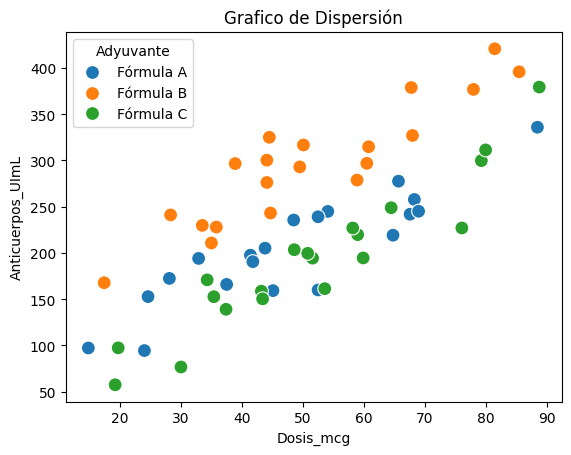

In [78]:
sns.scatterplot(data=datos, x='Dosis_mcg', y='Anticuerpos_UImL', hue='Adyuvante', s=100)
plt.title('Grafico de Dispersión')
plt.show()

Entregable 1.2: Un diagrama de caja (boxplot) que compare la distribución de los 
Anticuerpos_UImL según el tipo de Adyuvante.

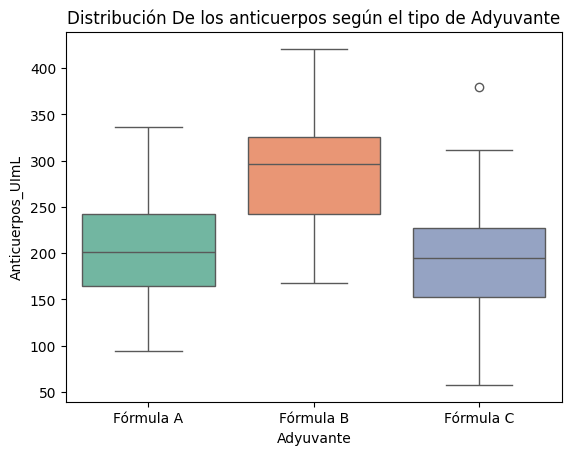

In [79]:
sns.boxplot(data=datos, x='Adyuvante', y='Anticuerpos_UImL', palette='Set2',hue='Adyuvante', legend=False)

plt.title('Distribución De los anticuerpos según el tipo de Adyuvante')
plt.xlabel('Adyuvante')
plt.ylabel('Anticuerpos_UImL')

plt.show()

# Fase 2: Regresión Lineal Simple

Entregable 2.1: Ajustar un modelo de regresión lineal. Presentar la ecuación de la 
recta de regresión ajustada, así como los coeficientes de determinación (R2) y 
correlación (r).

In [ ]:

resultado = stats.linregress(datos['Dosis_mcg'], datos['Anticuerpos_UImL'])


print(f"Pendiente(m): {resultado.slope:.4f}")
print(f"Intersección(b): {resultado.intercept:.4f}")
print(f"Coeficiente de correlación (r): {resultado.rvalue:.4f}")
print(f"Coeficiente de determinación (R²): {resultado.rvalue**2:.4f}")
print(f"Valor p: {resultado.pvalue:.20f}")

Pendiente(m): 3.3276
Intersección(b): 63.4659
Coeficiente de correlación (r): 0.7640
Coeficiente de determinación (R²): 0.5837
Valor p: 0.00000000


Entregable 2.2: Realizar la prueba de hipótesis para la pendiente (𝐻0:β1 = 0). 
Reportar el Valor-p y concluir si la dosis tiene un impacto significativo. 

In [81]:
import statsmodels.formula.api as smf

# OLS significa Ordinary Least Squares (Mínimos Cuadrados Ordinarios)
modelo = smf.ols(formula="Anticuerpos_UImL ~ Dosis_mcg", data=datos)

# 2. Ajustamos (entrenamos) el modelo a nuestros datos
resultados_ols = modelo.fit()

# 3. Mostramos el reporte estadístico completo
print(resultados_ols.summary())

                            OLS Regression Results                            
Dep. Variable:       Anticuerpos_UImL   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.577
Method:                 Least Squares   F-statistic:                     81.34
Date:                Tue, 26 May 2026   Prob (F-statistic):           1.24e-12
Time:                        11:04:14   Log-Likelihood:                -322.18
No. Observations:                  60   AIC:                             648.4
Df Residuals:                      58   BIC:                             652.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     63.4659     19.817      3.203      0.0

Entregable 2.3: Predicción con incertidumbre. Si la clínica planea estandarizar una 
dosis de 50 µg, reportar: 
  La estimación puntual de anticuerpos. 
  El Intervalo de Confianza al 95% (el rango donde se espera el promedio 
  poblacional). 
  El Intervalo de Predicción al 95% (el rango de respuesta esperado para un 
  paciente individual).

In [82]:
nueva_dosis = pd.DataFrame({'Dosis_mcg': [50]})

prediccion = resultados_ols.get_prediction(nueva_dosis)
intervalos = prediccion.summary_frame(alpha=0.05)

# ── Presentación formateada ──────────────────────────────
estimacion   = intervalos['mean'].values[0]
ic_inf       = intervalos['mean_ci_lower'].values[0]
ic_sup       = intervalos['mean_ci_upper'].values[0]
ip_inf       = intervalos['obs_ci_lower'].values[0]
ip_sup       = intervalos['obs_ci_upper'].values[0]

separador = "─" * 45

print(separador)
print(f"  PREDICCIÓN PARA DOSIS = 50 µg")
print(separador)
print(f"  Estimación puntual          {estimacion:>10.2f}  UI/mL")
print(separador)
print(f"  Intervalo de Confianza 95%")
print(f"  (promedio poblacional)")
print(f"    Límite inferior           {ic_inf:>10.2f}  UI/mL")
print(f"    Límite superior           {ic_sup:>10.2f}  UI/mL")
print(separador)
print(f"  Intervalo de Predicción 95%")
print(f"  (paciente individual)")
print(f"    Límite inferior           {ip_inf:>10.2f}  UI/mL")
print(f"    Límite superior           {ip_sup:>10.2f}  UI/mL")
print(separador)

─────────────────────────────────────────────
  PREDICCIÓN PARA DOSIS = 50 µg
─────────────────────────────────────────────
  Estimación puntual              229.84  UI/mL
─────────────────────────────────────────────
  Intervalo de Confianza 95%
  (promedio poblacional)
    Límite inferior               216.18  UI/mL
    Límite superior               243.51  UI/mL
─────────────────────────────────────────────
  Intervalo de Predicción 95%
  (paciente individual)
    Límite inferior               123.15  UI/mL
    Límite superior               336.54  UI/mL
─────────────────────────────────────────────


# Fase 3: ANOVA de un factor

Entregable 3.1: Plantear las hipótesis nula y alternativa (𝐻0: μ𝐴 = μ𝐵 = μ𝐶).

**Hipótesis nula (H0):** Los promedios de eficacia de la vacuna son iguales para los tres tipos de adyuvante.

**Hipótesis alternativa (H1):** Al menos uno de los promedios de eficacia difiere entre los tipos de adyuvante.

In [83]:
# Revisar los grupos de adyuvante
print('Tipos de adyuvante:', sorted(datos['Adyuvante'].unique()))
print('\nConteo por adyuvante:')
print(datos['Adyuvante'].value_counts())


Tipos de adyuvante: ['Fórmula A', 'Fórmula B', 'Fórmula C']

Conteo por adyuvante:
Adyuvante
Fórmula A    20
Fórmula B    20
Fórmula C    20
Name: count, dtype: int64


Entregable 3.2: Ejecutar el Análisis de Varianza (ANOVA de un factor) utilizando Python. Reportar el Estadístico F y el Valor-p.

In [84]:
# Preparar los datos para ANOVA
grupos = [
    datos.loc[datos['Adyuvante'] == ady, 'Anticuerpos_UImL']
    for ady in sorted(datos['Adyuvante'].unique())
]

# ANOVA de un factor
estadistico_f, valor_p = stats.f_oneway(*grupos)

print('ANOVA de un factor para eficacia según adyuvante')
print(f'Estadístico F: {estadistico_f:.4f}')
print(f'Valor-p: {valor_p:.9f}')

alpha = 0.05
if valor_p < alpha:
    print(f'Conclusión: valor-p < {alpha}, rechazamos H0.')
else:
    print(f'Conclusión: valor-p >= {alpha}, no rechazamos H0.')


ANOVA de un factor para eficacia según adyuvante
Estadístico F: 13.7251
Valor-p: 0.000013625
Conclusión: valor-p < 0.05, rechazamos H0.


Entregable 3.3: Conclusión estadística. Con un nivel de significancia α = 0.05, indicar si se rechaza la hipótesis nula.

**Conclusión:**
Con α = 0.05 y un valor-p = 0.000014 (p < 0.001), **se rechaza la hipótesis nula (H₀)**. 
Existe evidencia estadística suficiente para concluir que el tipo de adyuvante **sí altera significativamente** la eficacia de la vacuna. 
La Fórmula B genera en promedio 295.9 UI/mL, superando a la Fórmula A (204.4 UI/mL) y a la Fórmula C (193.5 UI/mL).

# Fase 4: Reporte Ejecutivo

**Entregable 4.1:** Reporte ejecutivo para la junta directiva.

---

La regresión lineal confirma que la dosis impacta directamente la respuesta inmune: cada microgramo adicional aporta **3.33 UI/mL** de anticuerpos (*r* = 0.764, *p* < 0.001). 
Para la dosis estándar de **50 µg** se proyectan **229.8 UI/mL** (IC 95%: 216.2 – 243.5). **Se recomienda estandarizar en 50 µg.**

El ANOVA demuestra diferencias significativas entre adyuvantes (*F* = 13.73, *p* < 0.001): 
Fórmula A: 204.4 UI/mL | Fórmula B: **295.9 UI/mL** | Fórmula C: 193.5 UI/mL. 
**La Fórmula B supera a sus competidoras en más del 45% y debe ser la elegida para producción masiva.**

---
> **Decisión:** Proceder a producción con **50 µg + Fórmula B**. Los datos no dejan margen de duda.